In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

from trips.utilities.weights import smoothed_holder_weights


from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
from pgkbsolver import MMGKB, IASGKB
from f2019solver import MM2019FGK2019, IASFGK2019, MMFGK2019


# Setup toy problem

In [53]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

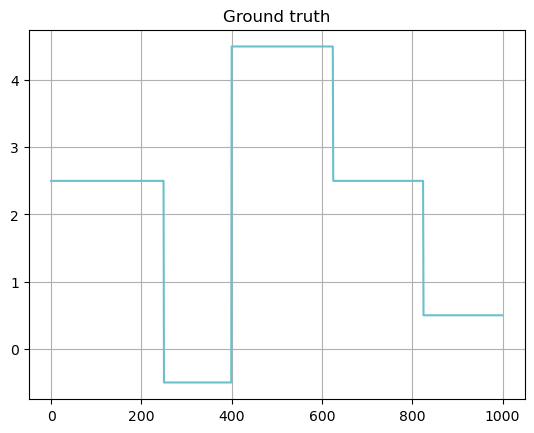

In [54]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [55]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [56]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

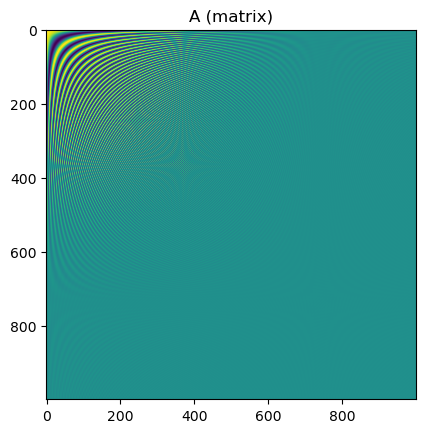

In [57]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [58]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

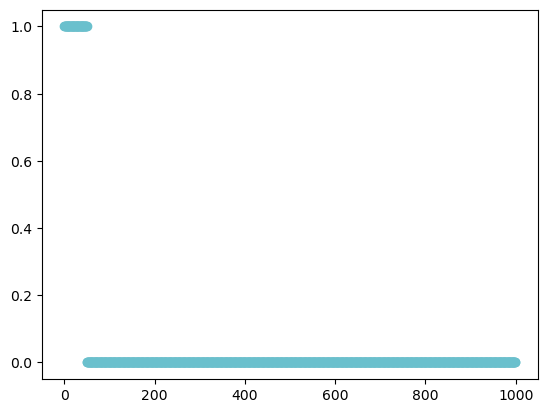

In [59]:
plt.scatter(grid, mask)
plt.show()

In [60]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

In [61]:
noise_var

0.13265734898578718

In [62]:
# # Inverse DCT reconstruction
# plt.plot(A.T @ b)
# plt.plot(ground_truth, color="k")
# plt.show()

In [63]:
# # # Other way of generating the data

# # Generate synthetic data
# np.random.seed(0)
# A = P @ F
# b_true = A @ ground_truth
# noise_sigma = 0.2
# b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])
# noise_var = noise_sigma**2

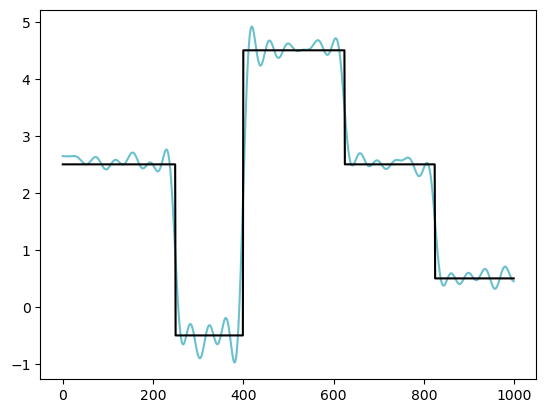

In [64]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [65]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
# Kmat = Kmat/np.linalg.norm(Kmat)

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = None


#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

mmgks_weight_params2019 = {
    "q": q,
    "tau1": 1e-10,
    "tau2": 1e-16,
}

iasgks_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}



Atilde = A @ _Lpinv
Ltilde = np.eye(_Lpinv.shape[1])

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
# mmfk2019_solver = MM2019FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk2019_solver = MMFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K)
#mmfk2019xx_solver = MM2019FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasfk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasfk2019_solver = IASFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K)
# iasfk2019xx_solver = IASFGK2019(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
iasgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# AK = A @ K.A
# AKpinv = jlinops.QRPinvOperator(AK)
# xker = K @ (AKpinv @ b)
xker = None

# Run all methods

In [66]:
n_its = 125
method = "dp"

ksparsity = 15

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

mm_pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


mm_data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

mm_resdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)
print("Finished S-GKS (restarted)")


mm_recdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


mm_fkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


mm_fk2019data = mmfk2019_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


# mm_fk2019xdata = mmfk2019x_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )

# print("Finished FK Solver")



# mm_fk2019xxdata = mmfk2019xx_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params2019, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )

# print("Finished FK Solver")

mm_gkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")





# Also do IAS weights

ias_pdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


ias_data = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

ias_resdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)
print("Finished S-GKS (restarted)")


ias_recdata = iasgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


ias_fkdata = iasfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


ias_fk2019data = iasfk2019_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")


# ias_fk2019xxdata = iasfk2019xx_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=1e-13,
#                                                  regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )

# print("Finished FK Solver")


ias_gkbdata = iasgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=iasgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine_invertible/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
124.40727283092774
166.48415797930937
177.0657068825644
183.53329151157297
186.26237717273654
186.87323669768
187.00991144714314
187.04029536267657
187.04839803235038
187.05186901644396
187.05247696322593
187.05266904887517
187.05270689663004
187.05271893668842
187.05272227482496
187.05272302566507
187.05272316261212
187.05272318798006
187.0527231927718
187.05272319316552
187.0527231932013
187.05272319320295
187.052723193203
187.05272319320335
187.05272319320332
187.05272319320295
187.05272319320284
187.05272319320332
187.05272319320326
187.0527231932028
187.05272319320287
187.05272319320278
187.05272319320272
187.05272319320315
187.05272319320306
187.05272319320295
187.052723193203
187.052723193203
187.05272319320306
187.052723193203
187.05272319320298
187.05272319320304
187.052723193203
187.052723193203
187.05272319320306
187.052723193203
187.05272319320306
187.052723193203
187.05272319320304
187.05272319320304
187.052723193203
187.0527231932

734.4247114348133
773.4913540627327
792.7646435688165
786.7947212547227
678.4096966018841
398.1030990218177
261.6985788419615
222.5772537620482
207.12262435777706
199.1489349912947
194.4712497396449
191.68058160550132
189.98769984019867
188.9407545638505
188.3192580745528
187.93155030095286
187.67406298505784
187.50640959098223
187.3773626339308
187.25679805816196
187.13438220593392
187.03423039306728
186.96873930334675
186.92695705730347
186.90215045553626
186.88283133917605
186.8678029119946
186.86570858542063
186.87507125576715
186.89381598965608
186.91736376635816
186.9370501948805
186.95321071633865
186.96858885412058
186.98339953185004
186.99530261963395
187.005226466949
187.0143463042034
187.02335563902187
187.03179454279942
187.0382934908616
187.0430259484341
187.0470223036739
187.05021945655372
187.0521144980719
187.05344174096933
187.0546805216003
187.05544264799784
187.05577245421875
187.05598119143846
187.0561220229203
187.05598952199165
187.05550868385896
187.0549666846016

1e-07
1e-07
13.164220746723553
21.716753578605964
28.51758520237873
33.91638768982364
37.535910200294744
40.13287304107144
42.07986696823934
43.67210272447278
44.95047009097585
46.02225821262528
46.92967162139143
47.71172720414345
48.39053670886732
48.985456010083716
49.5134975056705
49.983726407836855
50.40647444566302
50.78808953668917
51.134718000011624
51.450689181959056
51.740289897261825
52.006419137100195
52.25209385364452
52.47925373278106
52.69026679525919
52.886519856459714
53.06964199540767
53.240829030672714
53.40121517049947
53.55174233110082
53.693304885082725
53.826658907218764
53.952468506719086
54.071354855185184
54.183861785026544
54.29047450795669
54.391640673227876
54.48775819606911
54.57918856983291
54.666261994188396
54.74927870459109
54.8285104273296
54.90420938208377
54.97660277008571
55.04590179837025
55.11229837888316
55.17597047236341
55.23708119076631
55.29578172036239
55.35221100156928
55.40649827708108
55.45876266623574
55.50911519607139
55.55765844380824


...

1000000.0


generating basis...: 100%|██████████| 124/124 [00:00<00:00, 1561.99it/s]


1000000.0


generating basis...: 100%|██████████| 125/125 [00:00<00:00, 1558.95it/s]


1000000.0
Finished P-GKB


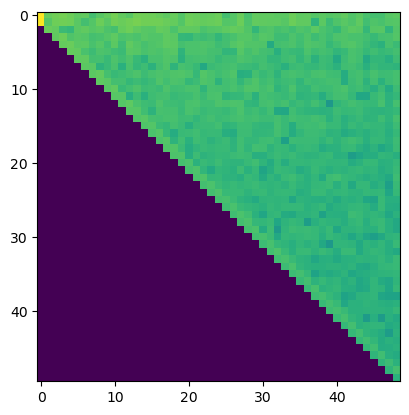

In [75]:
plt.imshow(np.log( np.abs( mm_fk2019data["M"]) + 1e-12) )

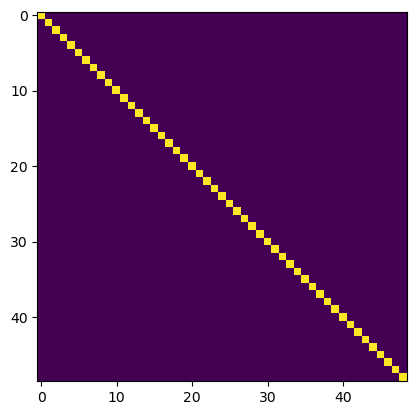

In [76]:
plt.imshow( (mm_fk2019data["V"].T @ mm_fk2019data["V"])[:58,:58]  )
plt.show()

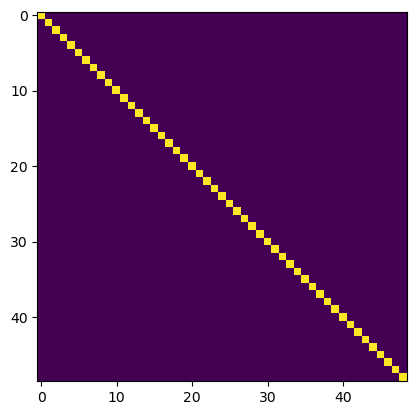

In [77]:
plt.imshow( mm_fk2019data["V"].T @ mm_fk2019data["V"]  )
plt.show()

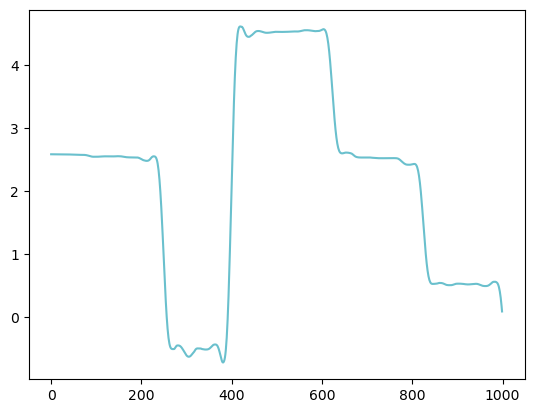

In [78]:
plt.plot(mm_fk2019data["x"])
plt.show()

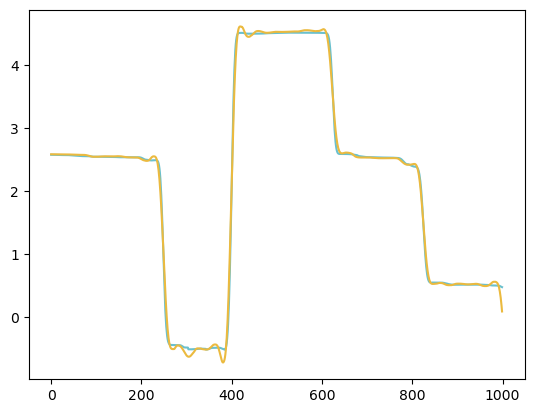

In [79]:
plt.plot(mm_fkdata["x"])
plt.plot(mm_fk2019data["x"])
plt.show()

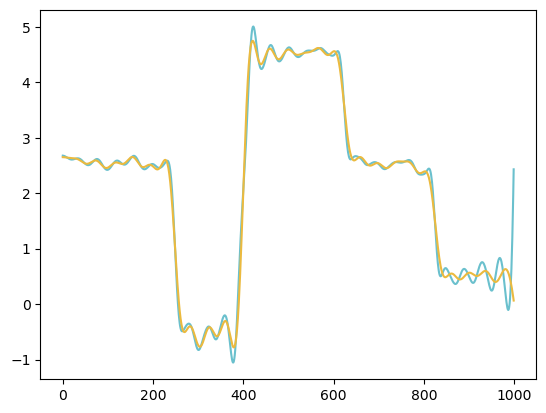

In [80]:
plt.plot(ias_fkdata["x"])
# plt.plot(_Lpinv @ ias_fk2019xdata["x"])
plt.plot(ias_fk2019data["x"])
plt.show()

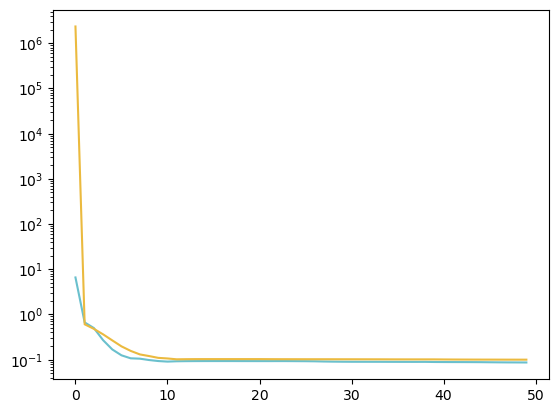

In [81]:
plt.semilogy(mm_fkdata["rre_history"])
plt.semilogy(mm_fk2019data["rre_history"])
plt.show()

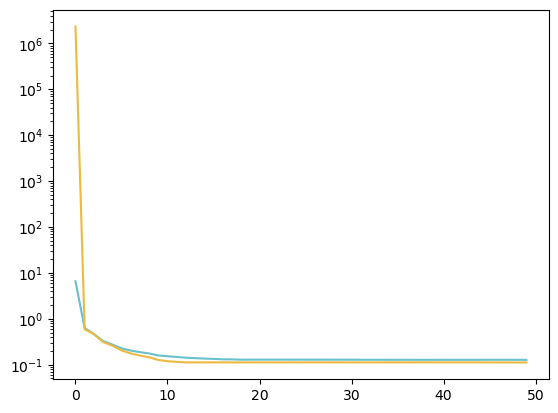

In [82]:
plt.semilogy(ias_fkdata["rre_history"])
plt.semilogy(ias_fk2019data["rre_history"])
plt.show()

In [83]:
ias_fkdata["broke_down"]

True

In [84]:
ias_fkdata["broke_down_idx"]

49

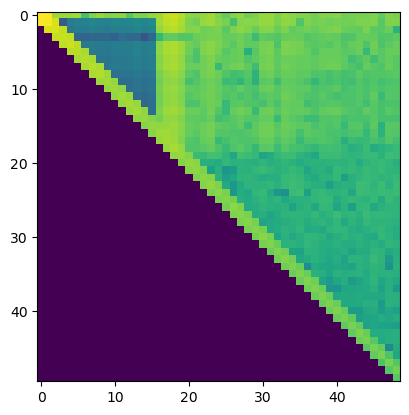

In [85]:
plt.imshow(np.log( np.abs( ias_fkdata["M"][:120,:120]) + 1e-12) )

In [86]:
np.linalg.norm((iasfk_solver.A @ ias_fkdata["Z"]) - (ias_fkdata["U"] @ ias_fkdata["M"])  )

1.6952823592470446e-10

In [87]:
np.linalg.norm((iasfk_solver.A.T @ ias_fkdata["U"][:,:-1]) - (ias_fkdata["V"] @ ias_fkdata["T"])  )

1.0375758062068001e-14

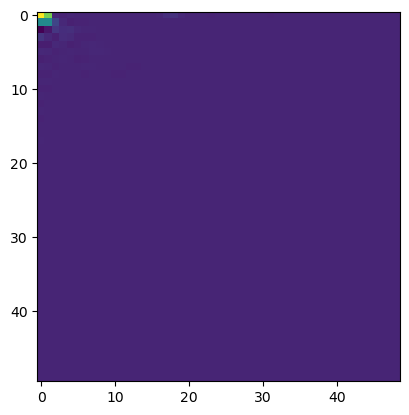

In [88]:
plt.imshow(iasfk_solver.A @ ias_fkdata["Z"])
plt.show()

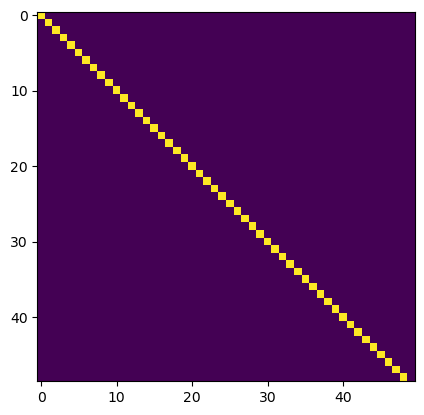

In [89]:
plt.imshow( ( ias_fkdata["V"].T @ (iasfk_solver.A.T @ ias_fkdata["U"] ) )[:50,:50] )
plt.show()

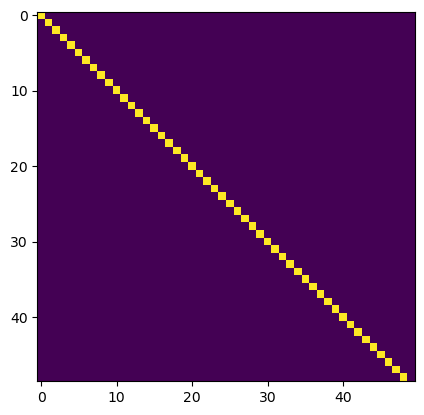

In [90]:
plt.imshow(  np.log(np.abs(( ias_fkdata["V"].T @ (iasfk_solver.A.T @ ias_fkdata["U"] ) ) + 1e-12 ))[:60,:60] )
plt.show()

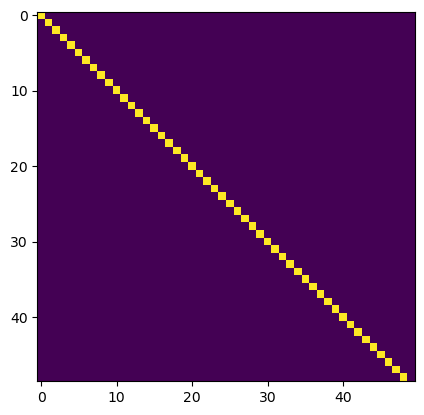

In [91]:
plt.imshow(  np.log(np.abs(( mm_fkdata["V"].T @ (mmfk_solver.A.T @ mm_fkdata["U"] ) ) + 1e-12 ))[:60,:60] )
plt.show()

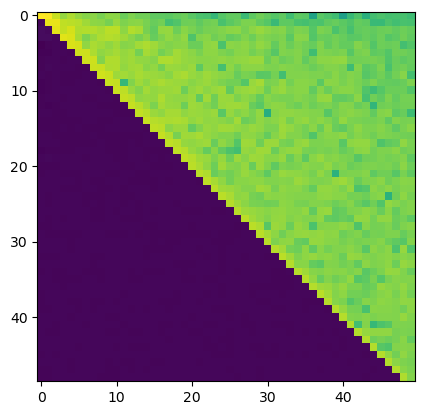

In [92]:
plt.imshow(  np.log(np.abs(( mm_fk2019data["V"].T @ (mmfk2019_solver.A.T @ mm_fk2019data["U"] ) ) + 1e-12 ))[:60,:60] )
plt.show()

# Make plots

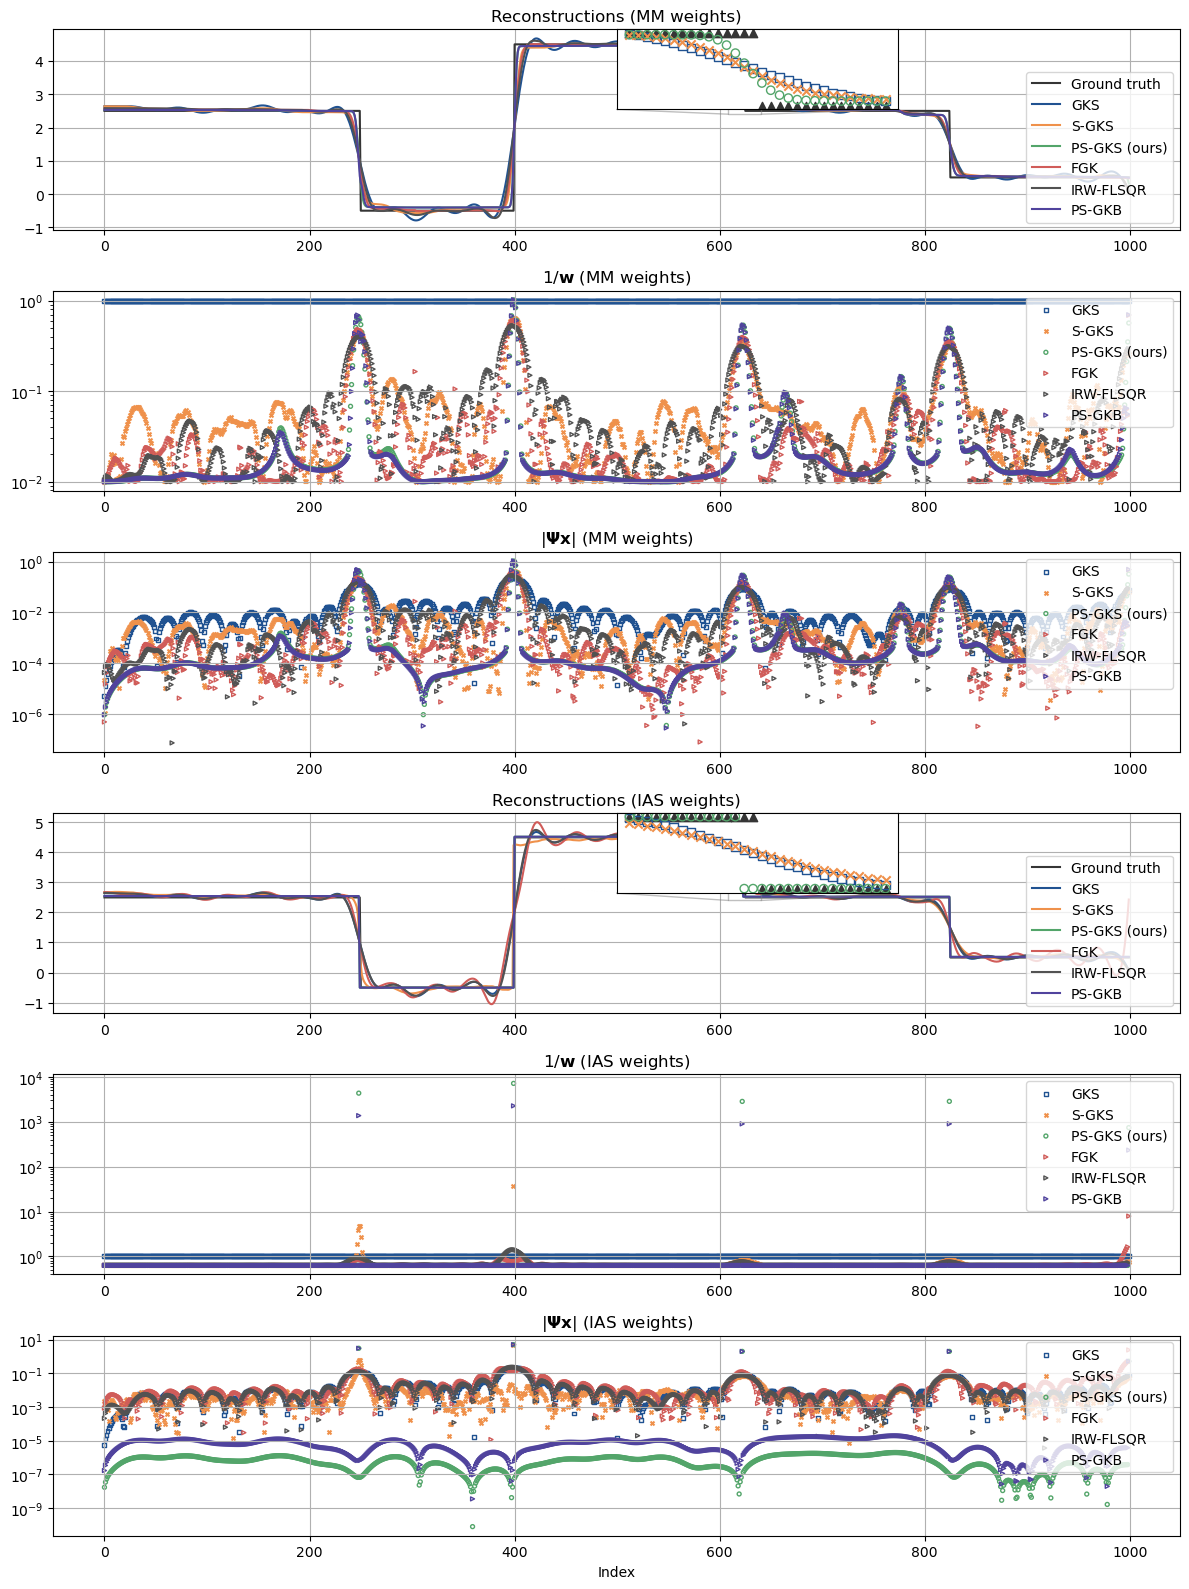

In [121]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 2*8))
gs = gridspec.GridSpec(6, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_data["x"], label="S-GKS", color="C5")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_pdata["x"], label="PS-GKS (ours)", color="C4")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_fkdata["x"], label="FGK", color="C6")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_fk2019data["x"], label="IRW-FLSQR", color="C8")
ax1.plot([i for i in range(len(mm_data["x"]))], mm_gkbdata["x"], label="PS-GKB", color="C7")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], mm_data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], mm_pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
ax1.set_title('Reconstructions (MM weights)')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_fkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_fk2019data['w'], label="IRW-FLSQR", color="C8", s=8, marker=">", facecolors="none")
ax2.scatter([i for i in range(len(mm_data["w"]))], 1.0/mm_gkbdata['w'], label="PS-GKB", color="C7", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$ (MM weights)")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()




ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_pdata['x']), label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_fkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_fk2019data['x']), label="IRW-FLSQR", color="C8", s=8, marker=">", facecolors="none")
ax10.scatter([i for i in range(len(mm_data["w"]))], np.abs(L @ mm_gkbdata['x']), label="PS-GKB", color="C7", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$ (MM weights)")
# ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()







# Combine the first two subplots at positions (0,0) and (0,1)
ax22 = fig.add_subplot(gs[3])
ax22.plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax22.plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_data["x"], label="S-GKS", color="C5")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_pdata["x"], label="PS-GKS (ours)", color="C4")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_fkdata["x"], label="FGK", color="C6")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_fk2019data["x"], label="IRW-FLSQR", color="C8")
ax22.plot([i for i in range(len(mm_data["x"]))], ias_gkbdata["x"], label="PS-GKB", color="C7")

inset_ax = ax22.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ias_data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
inset_ax.scatter([i for i in range(len(mm_data["x"]))][inset_low_coord:inset_high_coord], ias_pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
inset_ax.grid()

ax22.indicate_inset_zoom(inset_ax)
ax22.legend(loc="lower right")
ax22.set_title('Reconstructions (IAS weights)')
ax22.grid()


ax33 = fig.add_subplot(gs[4])
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_fkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_fk2019data['w'], label="IRW-FLSQR", color="C8", s=8, marker=">", facecolors="none")
ax33.scatter([i for i in range(len(mm_data["w"]))], 1.0/ias_gkbdata['w'], label="PS-GKB", color="C7", s=8, marker=">", facecolors="none")
ax33.set_title("$1/\\mathbf{w}$ (IAS weights)")
#ax2.set_xlabel("Index")
ax33.set_yscale("log")
ax33.legend(loc="upper right")
ax33.grid()




ax44 = fig.add_subplot(gs[5])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_pdata['x']), label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_fkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_fk2019data['x']), label="IRW-FLSQR", color="C8", s=8, marker=">", facecolors="none")
ax44.scatter([i for i in range(len(ias_data["w"]))], np.abs(L @ ias_gkbdata['x']), label="PS-GKB", color="C7", s=8, marker=">", facecolors="none")
ax44.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$ (IAS weights)")
ax44.set_xlabel("Index")
ax44.set_yscale("log")
ax44.legend(loc="upper right")
ax44.grid()




# Adjust layout
fig.tight_layout()
# fig.savefig("1d_cosine_example_reconstructions_all.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_reconstructions_all.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


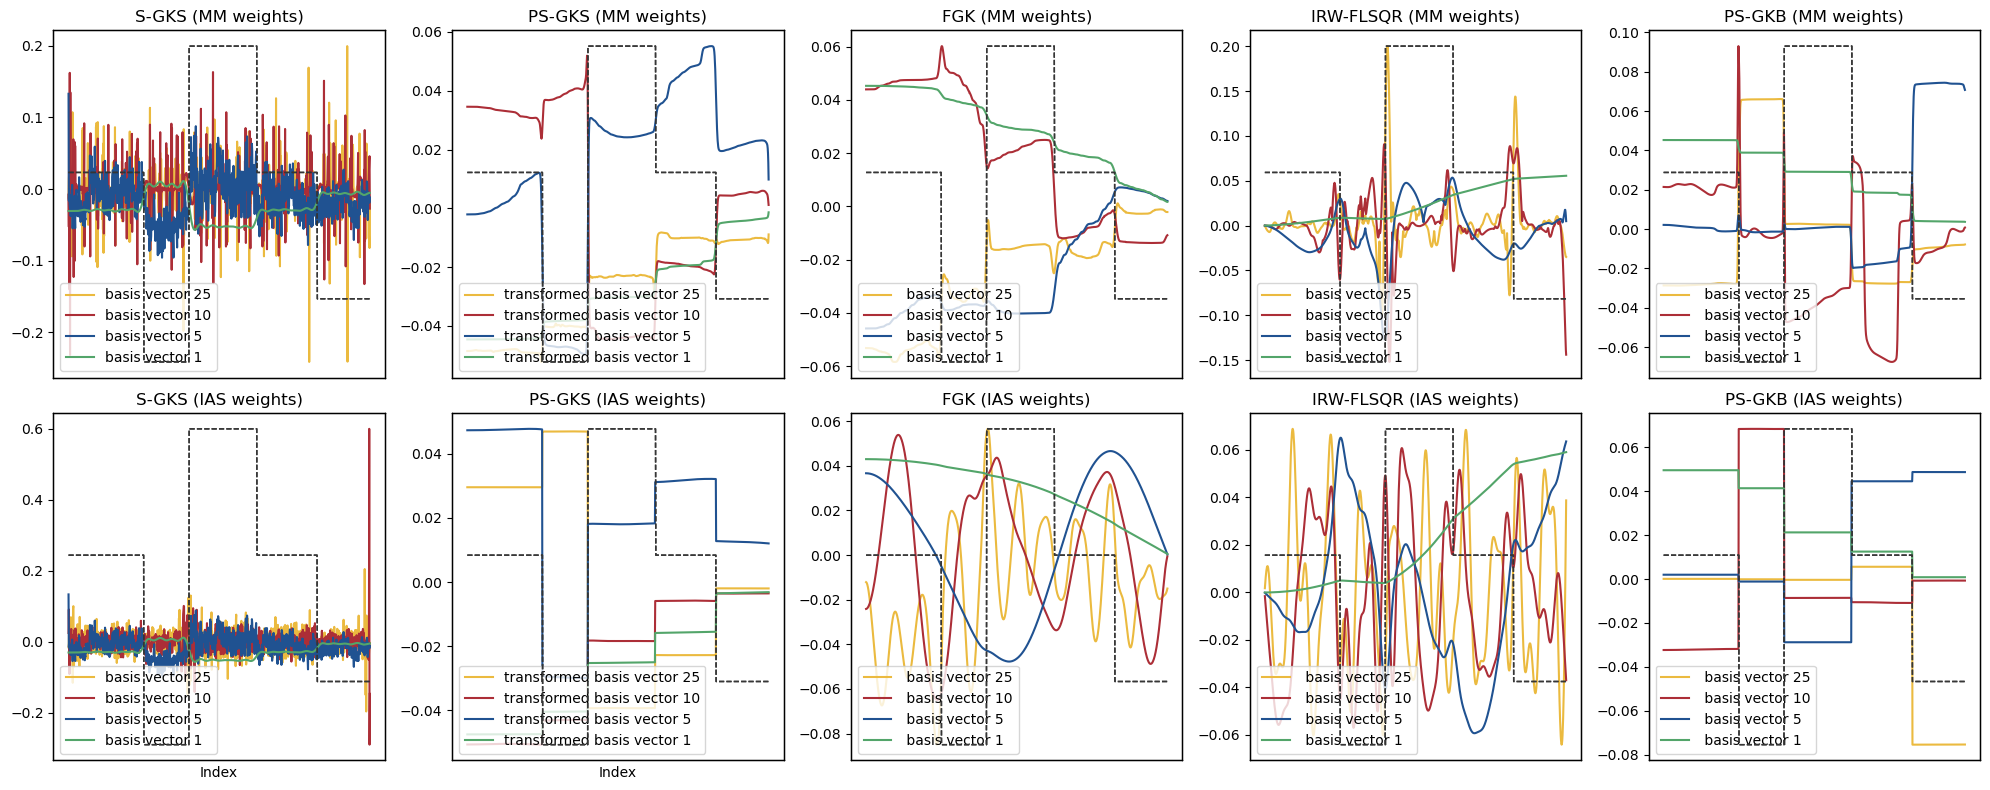

In [120]:
fig, axs = plt.subplots(2,5, figsize=(20,8))

loc = "lower left"
truth_lw = 1

kks = [0, 4, 9, 24]

for j, kk in enumerate(reversed(kks)):

    axs[0,0].plot(mm_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[0,0].legend(loc=loc)
    axs[0,0].set_xticks([])
    axs[0,0].set_title("S-GKS (MM weights)")
    axst = axs[0,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,1].plot(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk] / np.linalg.norm(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[0,1].legend(loc=loc)
    axs[0,1].set_xticks([])
    axs[0,1].set_title("PS-GKS (MM weights)")
    axst = axs[0,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])


for j, kk in enumerate(reversed(kks)):

    axs[0,2].plot(mm_fkdata["Z"][:,kk] / np.linalg.norm(mm_fkdata["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[0,2].legend(loc=loc)
    axs[0,2].set_xticks([])
    axs[0,2].set_title("FGK (MM weights)")
    axst = axs[0,2].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,3].plot(mm_fk2019data["Z"][:,kk] / np.linalg.norm(mm_fk2019data["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[0,3].legend(loc=loc)
    axs[0,3].set_xticks([])
    axs[0,3].set_title("IRW-FLSQR (MM weights)")
    axst = axs[0,3].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])


for j, kk in enumerate(reversed(kks)):

    axs[0,4].plot(  (mm_gkbdata["Lopinv"] @ mm_gkbdata["V"][:,kk]) / np.linalg.norm((mm_gkbdata["Lopinv"] @ mm_gkbdata["V"][:,kk])), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[0,4].legend(loc=loc)
    axs[0,4].set_xticks([])
    axs[0,4].set_title("PS-GKB (MM weights)")
    axst = axs[0,4].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])





for j, kk in enumerate(reversed(kks)):

    axs[1,0].plot(ias_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[1,0].legend(loc=loc)
    axs[1,0].set_xticks([])
    axs[1,0].set_xlabel("Index")
    axs[1,0].set_title("S-GKS (IAS weights)")
    axst = axs[1,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,1].plot(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk] / np.linalg.norm(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[1,1].legend(loc=loc)
    axs[1,1].set_xticks([])
    axs[1,1].set_title("PS-GKS (IAS weights)")
    axs[1,1].set_xlabel("Index")
    axst = axs[1,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    axst.set_yticks([])
    #axst.set_yticks([0, 2, 4, 6])



for j, kk in enumerate(reversed(kks)):

    axs[1,2].plot(ias_fkdata["Z"][:,kk] / np.linalg.norm(ias_fkdata["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[1,2].legend(loc=loc)
    axs[1,2].set_xticks([])
    axs[1,2].set_title("FGK (IAS weights)")
    axst = axs[1,2].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])




for j, kk in enumerate(reversed(kks)):

    axs[1,3].plot(ias_fk2019data["Z"][:,kk] / np.linalg.norm(ias_fk2019data["Z"][:,kk]), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[1,3].legend(loc=loc)
    axs[1,3].set_xticks([])
    axs[1,3].set_title("IRW-FLSQR (IAS weights)")
    axst = axs[1,3].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])




for j, kk in enumerate(reversed(kks)):

    axs[1,4].plot(  (ias_gkbdata["Lopinv"] @ ias_gkbdata["V"][:,kk]) / np.linalg.norm((ias_gkbdata["Lopinv"] @ ias_gkbdata["V"][:,kk])), label=f" basis vector {kk+1}", color=f"C{j+1}")
    axs[1,4].legend(loc=loc)
    axs[1,4].set_xticks([])
    axs[1,4].set_title("PS-GKB (IAS weights)")
    axst = axs[1,4].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



fig.tight_layout()
# fig.savefig("1d_cosine_example_basis_vectors_all.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_basis_vectors_all.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

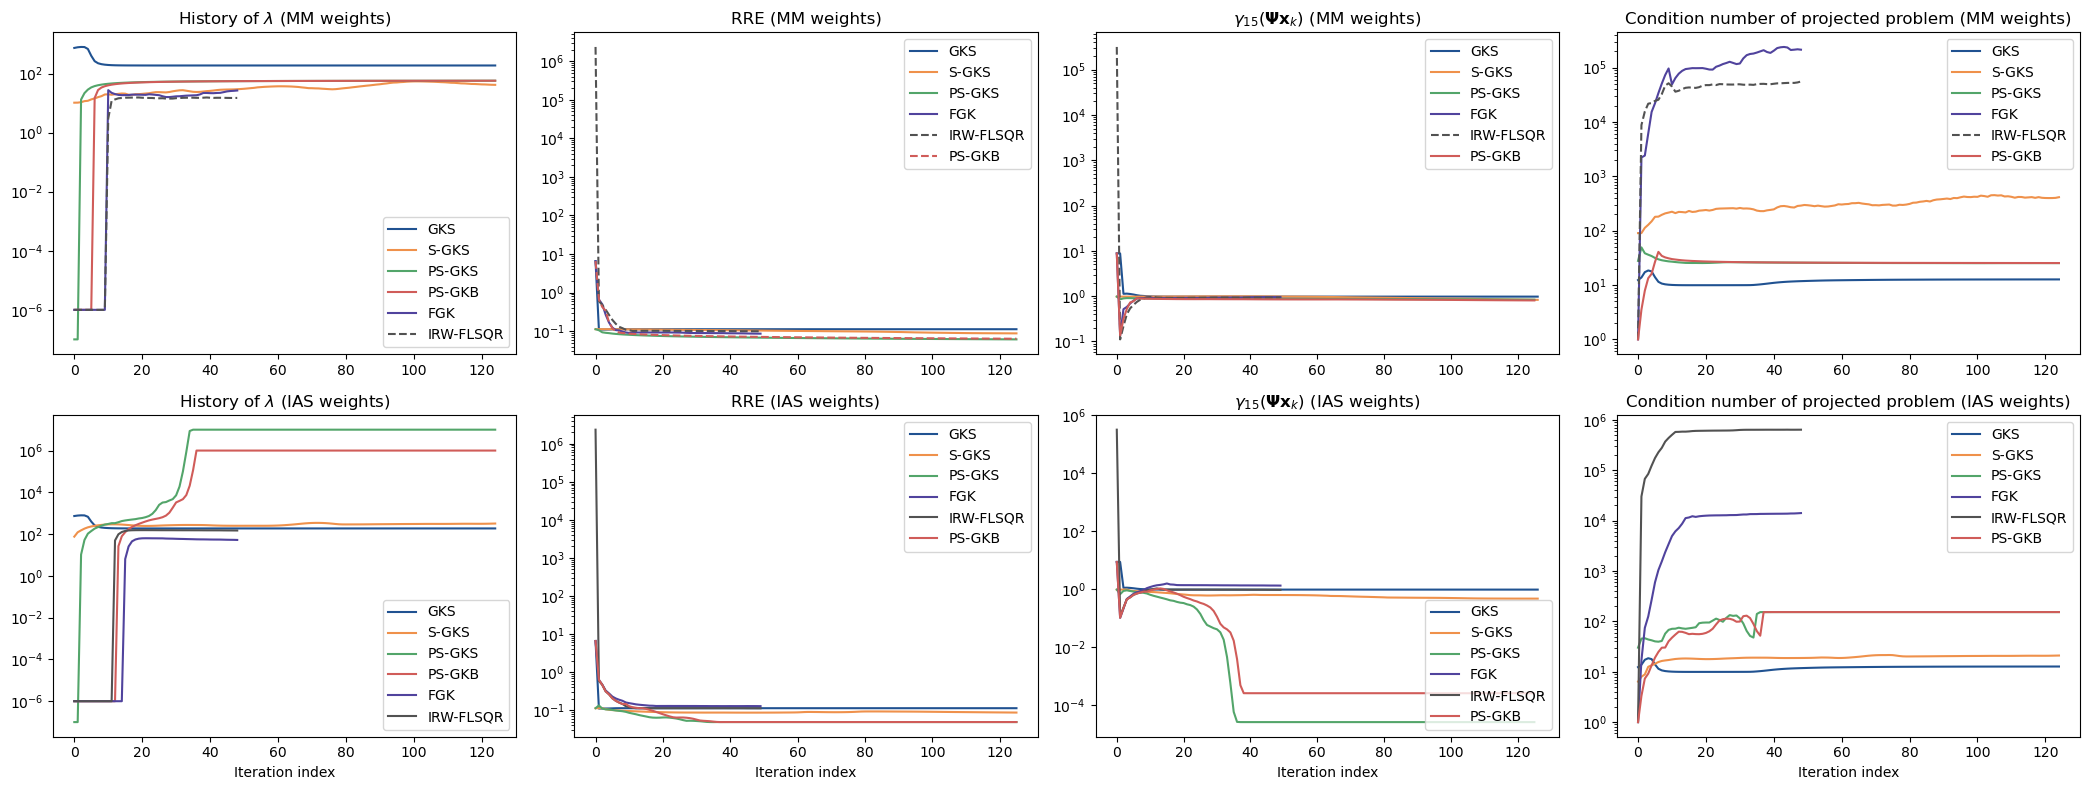

In [117]:
fig, axs = plt.subplots(2,4,figsize=(21,8))

loc="upper right"

# Lambda history

axs[0,0].semilogy([i for i in range(len(vdata["lambda_history"]))], vdata["lambda_history"], label="GKS", color="C3")
axs[0,0].plot([i for i in range(len(mm_data["lambda_history"]))], mm_data["lambda_history"], color="C5", label="S-GKS")
axs[0,0].plot([i for i in range(len(mm_pdata["lambda_history"]))], mm_pdata["lambda_history"], color="C4", label="PS-GKS")
axs[0,0].plot([i for i in range(len(mm_pdata["lambda_history"]))], mm_gkbdata["lambda_history"], color="C6", label="PS-GKB")
axs[0,0].plot([i for i in range(len(mm_fkdata["lambda_history"]))], mm_fkdata["lambda_history"], color="C7", label="FGK")
axs[0,0].plot([i for i in range(len(mm_fk2019data["lambda_history"]))], mm_fk2019data["lambda_history"], color="C8", label="IRW-FLSQR", ls="--")
#axs[0,0].plot([i for i in range(len(mm_gkbdata["lambda_history"]))], mm_gkbdata["lambda_history"], color="C6", label="PS-GKB", ls="--")
axs[0,0].legend(loc="lower right")
axs[0,0].set_title("History of $\lambda$ (MM weights)")


axs[1,0].semilogy([i for i in range(len(vdata["lambda_history"]))], vdata["lambda_history"], label="GKS", color="C3")
axs[1,0].plot([i for i in range(len(ias_data["lambda_history"]))], ias_data["lambda_history"], color="C5", label="S-GKS")
axs[1,0].plot([i for i in range(len(ias_pdata["lambda_history"]))], ias_pdata["lambda_history"], color="C4", label="PS-GKS")
axs[1,0].plot([i for i in range(len(ias_pdata["lambda_history"]))], ias_gkbdata["lambda_history"], color="C6", label="PS-GKB")
axs[1,0].plot([i for i in range(len(ias_fkdata["lambda_history"]))], ias_fkdata["lambda_history"], color="C7", label="FGK")
axs[1,0].plot([i for i in range(len(ias_fk2019data["lambda_history"]))], ias_fk2019data["lambda_history"], color="C8", label="IRW-FLSQR")
axs[1,0].legend(loc="lower right")
axs[1,0].set_xlabel("Iteration index")
axs[1,0].set_title("History of $\lambda$ (IAS weights)")

# RRE
axs[0,1].semilogy([i for i in range(len(vdata["rre_history"]))], vdata["rre_history"], label="GKS", color="C3")
axs[0,1].plot([i for i in range(len(mm_data["rre_history"]))], mm_data["rre_history"], color="C5", label="S-GKS")
#axs[0,1].plot([i for i in range(len(mm_resdata["rre_history"]))], mm_resdata["rre_history"], color="C5", label="S-GKS (restarting)", ls="--")
#axs[0,1].plot([i for i in range(len(mm_recdata["rre_history"]))], mm_recdata["rre_history"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,1].plot([i for i in range(len(mm_pdata["rre_history"]))], mm_pdata["rre_history"], color="C4", label="PS-GKS")
# axs[0,1].plot([i for i in range(len(mm_pdata["rre_history"]))], mm_gkbdata["rre_history"], color="C6", label="PS-GKB")
axs[0,1].plot([i for i in range(len(mm_fkdata["rre_history"]))], mm_fkdata["rre_history"], color="C7", label="FGK")
axs[0,1].plot([i for i in range(len(mm_fk2019data["rre_history"]))], mm_fk2019data["rre_history"], color="C8", label="IRW-FLSQR", ls="--")
axs[0,1].plot([i for i in range(len(mm_gkbdata["rre_history"]))], mm_gkbdata["rre_history"], color="C6", label="PS-GKB", ls="--")
axs[0,1].set_title("RRE (MM weights)")
axs[0,1].legend(loc=loc)


axs[1,1].semilogy([i for i in range(len(vdata["rre_history"]))], vdata["rre_history"], label="GKS", color="C3")
axs[1,1].plot([i for i in range(len(ias_data["rre_history"]))], ias_data["rre_history"], color="C5", label="S-GKS")
# axs[1,1].plot([i for i in range(len(ias_resdata["rre_history"]))], ias_resdata["rre_history"], color="C5", label="S-GKS (restarting)", ls="--")
# axs[1,1].plot([i for i in range(len(ias_recdata["rre_history"]))], ias_recdata["rre_history"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,1].plot([i for i in range(len(ias_pdata["rre_history"]))], ias_pdata["rre_history"], color="C4", label="PS-GKS")
axs[1,1].plot([i for i in range(len(ias_fkdata["rre_history"]))], ias_fkdata["rre_history"], color="C7", label="FGK")
axs[1,1].plot([i for i in range(len(ias_fk2019data["rre_history"]))], ias_fk2019data["rre_history"], color="C8", label="IRW-FLSQR")
axs[1,1].plot([i for i in range(len(ias_gkbdata["rre_history"]))], ias_gkbdata["rre_history"], color="C6", label="PS-GKB")
axs[1,1].set_title("RRE (IAS weights)")
axs[1,1].set_xlabel("Iteration index")
axs[1,1].legend(loc=loc)


# ksparsity
axs[0,2].semilogy([i for i in range(len(vdata["ksparsity_indices"]))], vdata["ksparsity_indices"], label="GKS", color="C3")
axs[0,2].plot([i for i in range(len(mm_data["ksparsity_indices"]))], mm_data["ksparsity_indices"], color="C5", label="S-GKS")
# axs[0,2].plot([i for i in range(len(mm_resdata["ksparsity_indices"]))], mm_resdata["ksparsity_indices"], color="C5", label="S-GKS (restarting)", ls="--")
# axs[0,2].plot([i for i in range(len(mm_recdata["ksparsity_indices"]))], mm_recdata["ksparsity_indices"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,2].plot([i for i in range(len(mm_pdata["ksparsity_indices"]))], mm_pdata["ksparsity_indices"], color="C4", label="PS-GKS")
axs[0,2].plot([i for i in range(len(mm_fkdata["ksparsity_indices"]))], mm_fkdata["ksparsity_indices"], color="C7", label="FGK")
axs[0,2].plot([i for i in range(len(mm_fk2019data["ksparsity_indices"]))], mm_fk2019data["ksparsity_indices"], color="C8", label="IRW-FLSQR", ls="--")
axs[0,2].plot([i for i in range(len(mm_pdata["ksparsity_indices"]))], mm_gkbdata["ksparsity_indices"], color="C6", label="PS-GKB")
axs[0,2].set_title("$\gamma_{15}(\\boldsymbol{\Psi} \mathbf{x}_{k})$ (MM weights)")
axs[0,2].legend(loc=loc)


axs[1,2].semilogy([i for i in range(len(vdata["ksparsity_indices"]))], vdata["ksparsity_indices"], label="GKS", color="C3")
axs[1,2].plot([i for i in range(len(ias_data["ksparsity_indices"]))], ias_data["ksparsity_indices"], color="C5", label="S-GKS")
# axs[1,2].plot([i for i in range(len(ias_resdata["ksparsity_indices"]))], ias_resdata["ksparsity_indices"], color="C5", label="S-GKS (restarting)", ls="--")
# axs[1,2].plot([i for i in range(len(ias_recdata["ksparsity_indices"]))], ias_recdata["ksparsity_indices"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,2].plot([i for i in range(len(ias_pdata["ksparsity_indices"]))], ias_pdata["ksparsity_indices"], color="C4", label="PS-GKS")
axs[1,2].plot([i for i in range(len(ias_fkdata["ksparsity_indices"]))], ias_fkdata["ksparsity_indices"], color="C7", label="FGK")
axs[1,2].plot([i for i in range(len(ias_fkdata["ksparsity_indices"]))], ias_fk2019data["ksparsity_indices"], color="C8", label="IRW-FLSQR")
axs[1,2].plot([i for i in range(len(ias_pdata["ksparsity_indices"]))], ias_gkbdata["ksparsity_indices"], color="C6", label="PS-GKB")
axs[1,2].set_title("$\gamma_{15}(\\boldsymbol{\Psi} \mathbf{x}_{k})$ (IAS weights)")
axs[1,2].set_xlabel("Iteration index")
axs[1,2].legend(loc="lower right")





# RRE
axs[0,3].semilogy([i for i in range(len(vdata["cond_ests"]))], vdata["cond_ests"], label="GKS", color="C3")
axs[0,3].plot([i for i in range(len(mm_data["cond_ests"]))], mm_data["cond_ests"], color="C5", label="S-GKS")
# axs[0,3].plot([i for i in range(len(mm_resdata["cond_ests"]))], mm_resdata["cond_ests"], color="C5", label="S-GKS (restarting)", ls="--")
# axs[0,3].plot([i for i in range(len(mm_recdata["cond_ests"]))], mm_recdata["cond_ests"], color="C5", label="S-GKS (recycling)", ls=":")
axs[0,3].plot([i for i in range(len(mm_pdata["cond_ests"]))], mm_pdata["cond_ests"], color="C4", label="PS-GKS")
axs[0,3].plot([i for i in range(len(mm_fkdata["cond_ests"]))], mm_fkdata["cond_ests"], color="C7", label="FGK")
axs[0,3].plot([i for i in range(len(mm_fk2019data["cond_ests"]))], mm_fk2019data["cond_ests"], color="C8", label="IRW-FLSQR", ls="--")
axs[0,3].plot([i for i in range(len(mm_pdata["cond_ests"]))], mm_gkbdata["cond_ests"], color="C6", label="PS-GKB")
axs[0,3].set_title("Condition number of projected problem (MM weights)")
axs[0,3].legend(loc=loc)


axs[1,3].semilogy([i for i in range(len(vdata["cond_ests"]))], vdata["cond_ests"], label="GKS", color="C3")
axs[1,3].plot([i for i in range(len(ias_data["cond_ests"]))], ias_data["cond_ests"], color="C5", label="S-GKS")
# axs[1,3].plot([i for i in range(len(ias_resdata["cond_ests"]))], ias_resdata["cond_ests"], color="C5", label="S-GKS (restarting)", ls="--")
# axs[1,3].plot([i for i in range(len(ias_recdata["cond_ests"]))], ias_recdata["cond_ests"], color="C5", label="S-GKS (recycling)", ls=":")
axs[1,3].plot([i for i in range(len(ias_pdata["cond_ests"]))], ias_pdata["cond_ests"], color="C4", label="PS-GKS")
axs[1,3].plot([i for i in range(len(ias_fkdata["cond_ests"]))], ias_fkdata["cond_ests"], color="C7", label="FGK")
axs[1,3].plot([i for i in range(len(ias_fk2019data["cond_ests"]))], ias_fk2019data["cond_ests"], color="C8", label="IRW-FLSQR")
axs[1,3].plot([i for i in range(len(ias_pdata["cond_ests"]))], ias_gkbdata["cond_ests"], color="C6", label="PS-GKB")
axs[1,3].set_title("Condition number of projected problem (IAS weights)")
axs[1,3].set_xlabel("Iteration index")
axs[1,3].legend(loc=loc)



#["ksparsity_indices"]


# axs[0,0].plot([i for i in range(len(ias_data["w"]))], ias_pdata["V"][:,kk])
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], vdata["x"], label="GKS", color="C3")
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], mm_data["x"], label="S-GKS", color="C5")
# axs[0,0].plot([i for i in range(len(mm_data["x"]))], mm_pdata["x"], label="PS-GKS", color="C4")


fig.tight_layout()
fig.savefig("1d_cosine_example_performance_all.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_performance_all.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()

In [43]:
mm_gkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history', 'ksparsity_indices'])

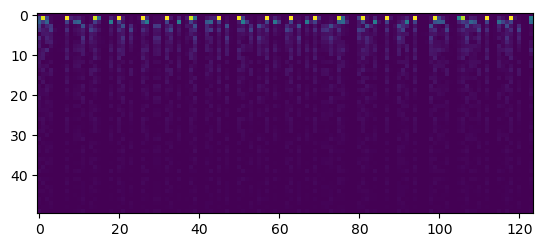

In [18]:
plt.imshow( np.abs((mmgkb_solver.A @ mm_gkbdata["Lopinv"]) @ mm_gkbdata["V"][:,:-1]) )
plt.show()

In [62]:
mm_gkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history', 'ksparsity_indices'])

In [19]:
(mmgkb_solver.A @ mm_gkbdata["Lopinv"]) @ mm_gkbdata["V"][:,:-1]

array([[ 1.21822445e-15, -1.70831475e-15,  6.51119965e-16, ...,
         1.40025799e-17,  7.00128994e-18,  2.20540633e-15],
       [ 1.84637082e+01,  7.62911922e+01,  1.71279605e+01, ...,
        -4.93896347e-02, -4.30781661e-02, -3.29755723e+01],
       [ 2.45965001e+01,  1.31077998e+01, -2.54492861e+01, ...,
        -8.39040030e-02,  1.62499283e-02,  2.68014656e+01],
       ...,
       [ 7.66904159e-01, -1.75843528e-01,  5.84260617e-01, ...,
         5.39143196e-02, -4.98658188e-02,  3.37387976e-02],
       [-2.53487893e-01, -4.13801167e-01, -6.01568522e-01, ...,
        -1.25490520e-01, -2.51949558e-02,  4.42137910e-01],
       [-1.64677670e+00,  4.21857377e-01, -3.45707618e-01, ...,
         5.37926500e-02, -2.59492950e-02, -6.85523881e-01]])

In [20]:
mm_gkbdata["U"].shape

(50, 126)

In [21]:
mm_gkbdata["B"].shape

(126, 125)

In [22]:
 mm_gkbdata["V"].shape

(999, 125)

In [23]:
np.linalg.norm( ( (mmgkb_solver.A @ mm_gkbdata["Lopinv"]) @ mm_gkbdata["V"] )  - (mm_gkbdata["U"] @ mm_gkbdata["B"]) )

2.1197568270726144e-13

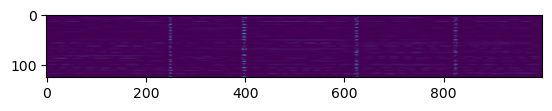

In [24]:
plt.imshow( np.abs( mm_gkbdata["V"] @ mm_gkbdata["B"][:-1] ).T )
plt.show()

In [25]:
mm_gkbdata["B"].shape

(126, 125)

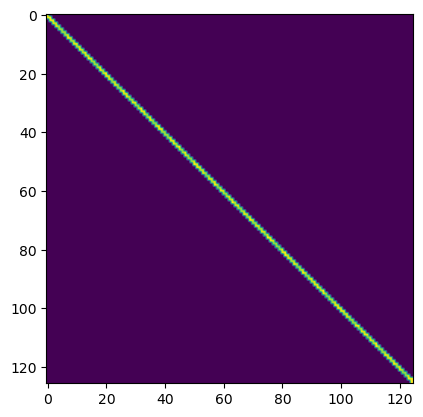

In [21]:
plt.imshow(np.log(np.abs(mm_gkbdata["B"]) + 1e-12))
plt.show()

In [88]:
mmfk_solver.A

<50x1000 _ScaledLinearOperator with dtype=float64>

In [90]:
mm_fkdata["V"].shape

(1000, 125)

In [92]:
mmfk_solver.A @ mm_fkdata["Z"]

array([[ 4.48082556e-14, -1.52348069e-14,  4.30159254e-14, ...,
         3.28185466e-19, -1.36743944e-20,  1.02557958e-20],
       [ 1.27241621e+03,  1.45217300e+03,  1.94164582e+03, ...,
         3.54584932e-03,  3.55864921e-03,  3.56569235e-03],
       [ 2.92328069e+03,  3.35372982e+02, -2.16730261e+02, ...,
         9.65437412e-03,  9.65254124e-03,  9.64778322e-03],
       ...,
       [ 2.41615117e+01,  2.69366235e+00,  3.00370138e+00, ...,
         2.12445005e-05,  2.07055703e-05,  2.03790846e-05],
       [-6.71153162e+00, -3.55474648e+00, -6.49123601e+00, ...,
         1.50178541e-04,  1.50208327e-04,  1.50567415e-04],
       [-5.51579736e+01, -3.94505294e+00,  5.69440512e-01, ...,
        -1.61069074e-05, -1.61061693e-05, -1.59280479e-05]])

In [93]:
mm_fkdata["U"] @ mm_fkdata["H"]

array([[-8.97909137e-04, -4.79930753e-04, -4.79024584e-04, ...,
         5.87561233e-08,  5.89892918e-08,  5.93654036e-08],
       [ 1.27204503e+03,  1.45197460e+03,  1.94144780e+03, ...,
         3.57025026e-03,  3.58314674e-03,  3.59034612e-03],
       [ 2.92323450e+03,  3.35348291e+02, -2.16754905e+02, ...,
         9.65700063e-03,  9.65517892e-03,  9.65043738e-03],
       ...,
       [ 2.64636918e+01,  3.92417327e+00,  4.23188893e+00, ...,
        -1.40199021e-04, -1.41345540e-04, -1.42698235e-04],
       [-3.70825977e+01, -1.97880245e+01, -2.26938635e+01, ...,
         2.16212502e-03,  2.17006873e-03,  2.18329654e-03],
       [-5.03167831e+01, -1.35744569e+00,  3.15216204e+00, ...,
        -3.46823944e-04, -3.48102175e-04, -3.50043055e-04]])

In [29]:
def to_upper_hessenberg(matrix):
    """
    Takes a matrix and returns its upper Hessenberg form.
    Elements below the first subdiagonal are set to zero.
    
    Parameters:
    matrix (np.ndarray): Input matrix (assumed to be 2D).
    
    Returns:
    np.ndarray: Upper Hessenberg matrix.
    """
    # Get the number of rows and columns
    rows, cols = matrix.shape
    
    # Make a copy of the matrix to zero out below the first subdiagonal
    hessenberg_matrix = np.copy(matrix)
    
    # Use NumPy's advanced indexing to zero out elements below the first subdiagonal
    i, j = np.tril_indices(rows, -2)
    hessenberg_matrix[i, j] = 0
    
    return hessenberg_matrix


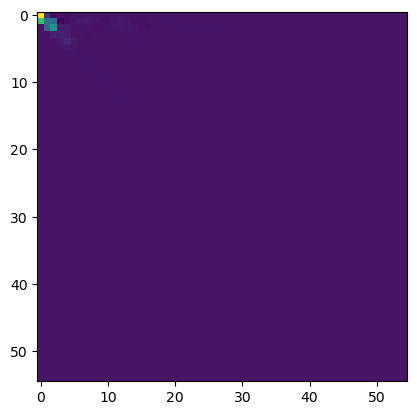

In [31]:
plt.imshow(to_upper_hessenberg(mm_fkdata["H"][:55,:55]))

In [22]:
plt.imshow( np.log(np.abs(to_upper_hessenberg(mm_fkdata["H"][:55,:55]))), vmin=None, vmax=None )
plt.colorbar()
plt.show()


NameError: name 'to_upper_hessenberg' is not defined

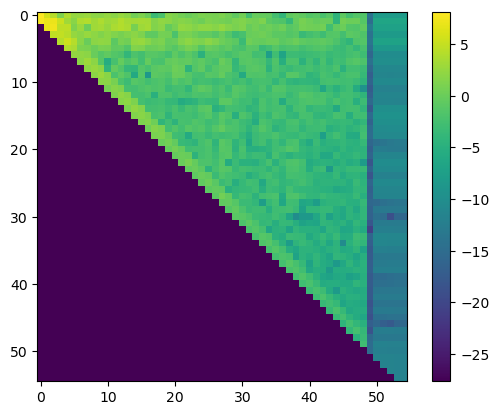

In [28]:
plt.imshow( np.log(np.abs(mm_fkdata["H"][:55,:55] + 1e-12)), vmin=None, vmax=None )
plt.colorbar()
plt.show()


In [37]:
np.linalg.norm( (mm_fkdata["V"].T @ mm_fkdata["V"]) - np.eye(mm_fkdata["V"].shape[1]) )

75.49834435253995

In [38]:
np.linalg.norm( (mm_fkdata["U"].T @ mm_fkdata["U"]) - np.eye(mm_fkdata["U"].shape[1]) )

76.87853843903876

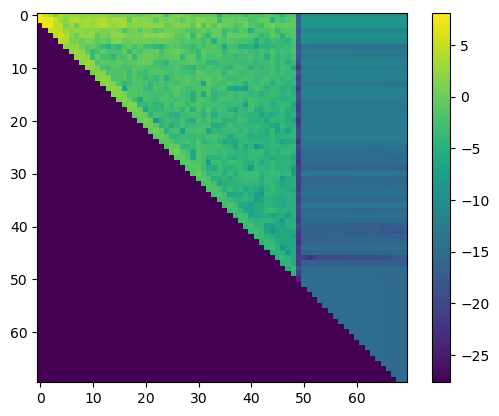

In [39]:
plt.imshow( np.log(np.abs(mm_fk2019data["H"][:70,:70] + 1e-12)), vmin=None, vmax=None )
plt.colorbar()
plt.show()


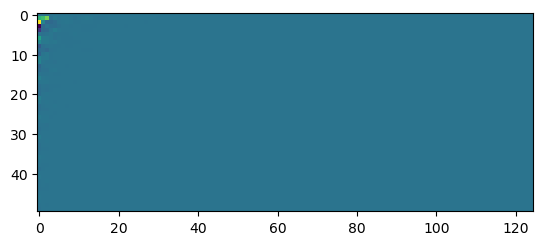

In [24]:
plt.imshow( mmfk_solver.A @ mm_fkdata["Z"] )
plt.show()

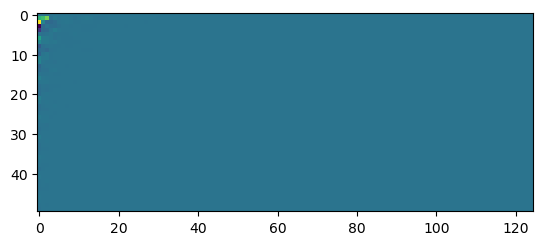

In [25]:
plt.imshow( mm_fkdata["U"] @ mm_fkdata["H"] )
plt.show()

In [26]:
np.linalg.norm((mmfk_solver.A @ mm_fkdata["Z"]) - (mm_fkdata["U"] @ mm_fkdata["H"])  )

0.045147896947712055

In [69]:
mm_fkdata.keys()

dict_keys(['x', 'V', 'U', 'H', 'Z', 'w', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history', 'ksparsity_indices'])

# Old plots

In [ ]:
fig, axs = plt.subplots(2,2, figsize=(15,8))

loc = "lower left"
truth_lw = 1

kks = [0, 4, 9, 24]

for j, kk in enumerate(reversed(kks)):

    axs[0,0].plot(mm_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[0,0].legend(loc=loc)
    axs[0,0].set_xticks([])
    axs[0,0].set_title("S-GKS (MM weights)")
    axst = axs[0,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[0,1].plot(mm_gkbdata["Lopinv"] @ mm_gkbdata["V"][:,kk] / np.linalg.norm(mm_pdata["Lopinv"] @ mm_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[0,1].legend(loc=loc)
    axs[0,1].set_xticks([])
    axs[0,1].set_title("PS-GKS (IAS weights)")
    axst = axs[0,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,0].plot(ias_data["V"][:,kk], label=f"basis vector {kk+1}", color=f"C{j+1}")
    axs[1,0].legend(loc=loc)
    axs[1,0].set_xticks([])
    axs[1,0].set_xlabel("Index")
    axs[1,0].set_title("S-GKS (MM weights)")
    axst = axs[1,0].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    #axst.set_yticks([0, 2, 4, 6])
    axst.set_yticks([])



for j, kk in enumerate(reversed(kks)):

    axs[1,1].plot(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk] / np.linalg.norm(ias_pdata["Lopinv"] @ ias_pdata["V"][:,kk]), label=f"transformed basis vector {kk+1}", color=f"C{j+1}")
    axs[1,1].legend(loc=loc)
    axs[1,1].set_xticks([])
    axs[1,1].set_title("PS-GKS (IAS weights)")
    axs[1,1].set_xlabel("Index")
    axst = axs[1,1].twinx()
    axst.plot(ground_truth, color="C9", alpha=0.7, ls="--", lw=truth_lw)
    axst.set_yticks([])
    #axst.set_yticks([0, 2, 4, 6])


fig.tight_layout()

plt.show()

In [ ]:
plt.plot(mmfkdata["x"], label="FGK", color="C9")
#plt.plot(mmfkdata["x"], label="FGK", color="C7")


In [22]:
plt.plot(mmfkdata["x"], label="FGK", color="C9")
#plt.plot(mmfkdata["x"], label="FGK", color="C7")


NameError: name 'mmfkdata' is not defined

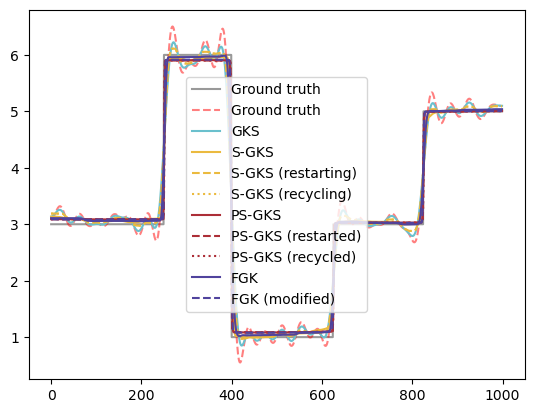

In [25]:
plt.plot(ground_truth, label="Ground truth", color="C9", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.plot(respdata["x"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["x"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.plot(mmfkdata["x"], label="FGK", color="C7")
plt.plot(rmmfkdata["x"], label="FGK (modified)", color="C7", ls="--")
plt.legend()
plt.show()

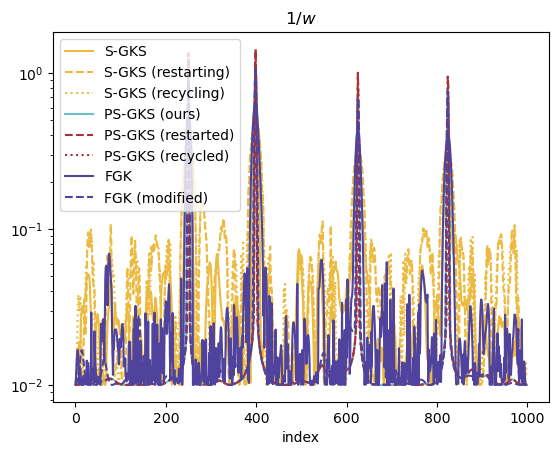

In [26]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.plot(1.0/respdata["w"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(1.0/recpdata["w"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(1.0/mmfkdata["w"], label="FGK", color="C7")
plt.semilogy(1.0/rmmfkdata["w"], label="FGK (modified)", ls="--", color="C7")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

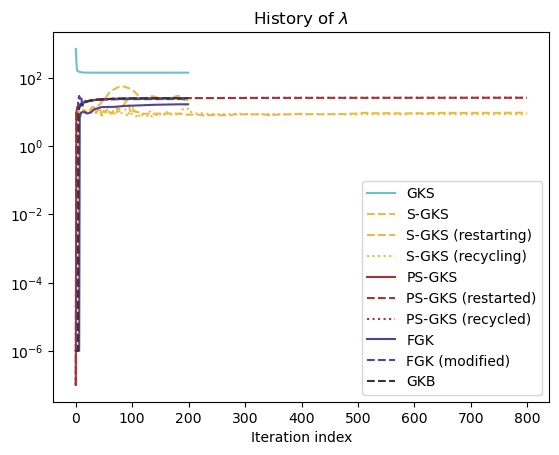

In [28]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["lambda_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["lambda_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", ls="--", alpha=1.0, color="C7")
plt.semilogy(mmgkbdata["lambda_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

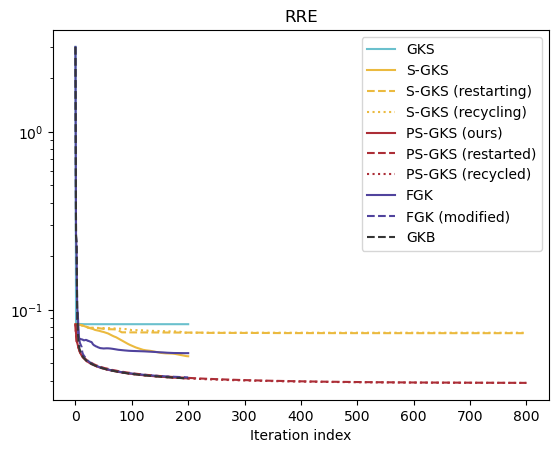

In [29]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["rre_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["rre_history"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["rre_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["rre_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

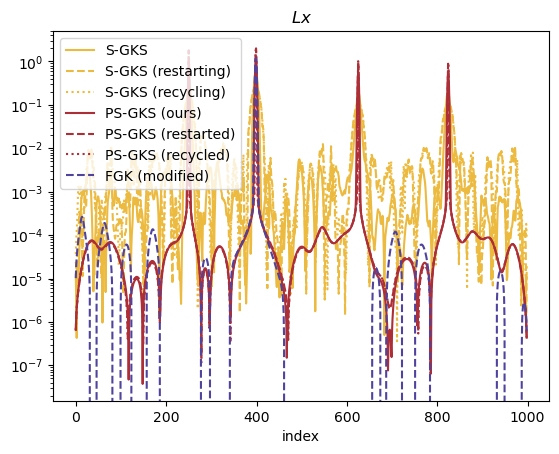

In [38]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(np.abs(L @ data['x']), label="S-GKS", color="C1")
plt.semilogy(np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(np.abs(L @ pdata['x']), label="PS-GKS (ours)", color="C2")
plt.plot(np.abs(L @ respdata["x"]), label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(np.abs(L @ recpdata["x"]), label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(L @ mmfkdata["x"], label="FGK", color="C7")
plt.semilogy(L @ rmmfkdata["x"], label="FGK (modified)", color="C7", ls="--")

plt.title("$L x$")
plt.xlabel("index")
plt.legend()
plt.show()

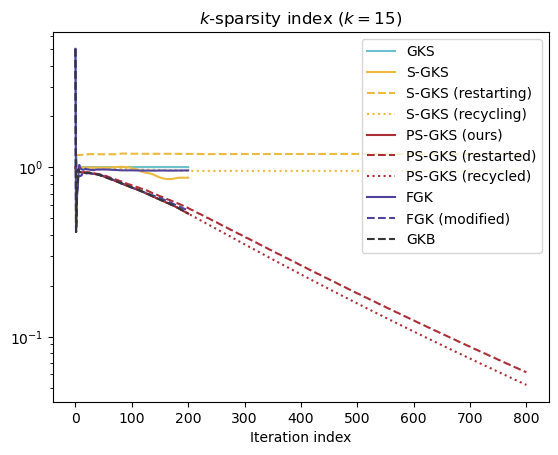

In [30]:
plt.semilogy(vdata["ksparsity_indices"], label="GKS", color="C0")
plt.semilogy(data["ksparsity_indices"], label="S-GKS", color="C1")
plt.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["ksparsity_indices"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ksparsity_indices"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ksparsity_indices"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["ksparsity_indices"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["ksparsity_indices"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("$k$-sparsity index ($k = 15$)")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

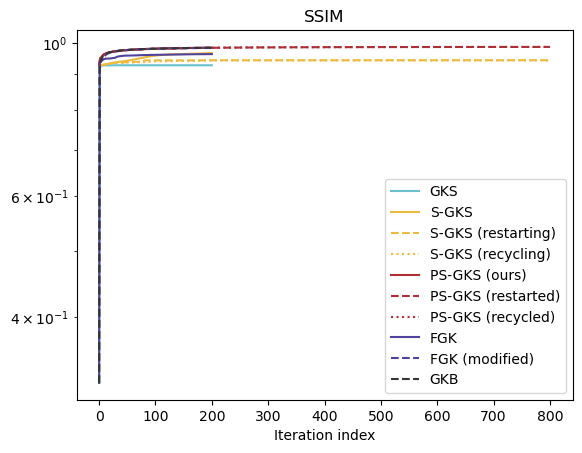

In [31]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ssim_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ssim_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["ssim_history"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["ssim_history"], label="FGK (modified)", alpha=1.0, color="C7", ls="--")
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

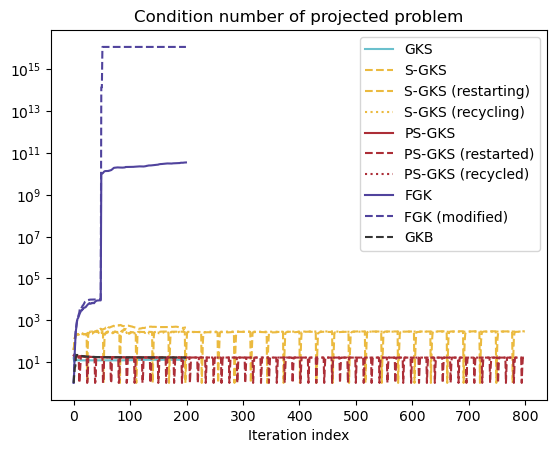

In [32]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["cond_ests"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["cond_ests"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.plot(mmfkdata["cond_ests"], label="FGK", color="C7")
plt.plot(rmmfkdata["cond_ests"], label="FGK (modified)", color="C7", ls="--")
plt.semilogy(mmgkbdata["cond_ests"], label="GKB", ls="--", alpha=1.0, color="C9")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

In [77]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 8))
# gs = gridspec.GridSpec(3, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS (ours)", color="C4")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :2])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()

# ax4 = fig.add_subplot(gs[1, 2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()



# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, 0])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend()



# ax6 = fig.add_subplot(gs[2, 1])
# ax6.plot(vdata["ssim_history"], label="GKS", color="C3")
# ax6.plot(data["ssim_history"], label="S-GKS", color="C5")
# ax6.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("SSIM")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[2, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# #fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


In [78]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 14))
# gs = gridspec.GridSpec(5, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
# ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()


# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, :])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
# ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
# ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# #ax3.set_xscale("log")
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend(loc="upper right")




# ax4 = fig.add_subplot(gs[4, :2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
# ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()





# ax6 = fig.add_subplot(gs[3, :])
# ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
# ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
# ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
# ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("$s$-sparsity $\sigma_s$, $s = 15$")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[4, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
# ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls="--")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


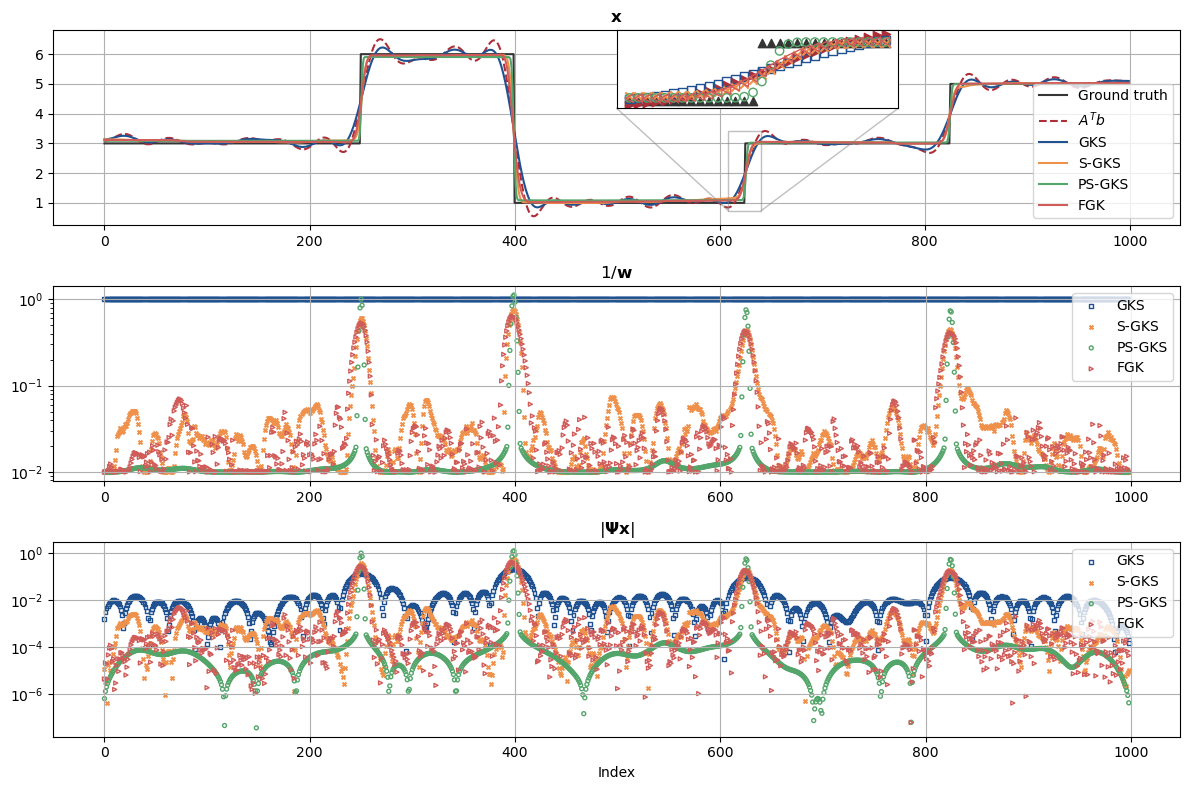

In [118]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(3, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
#ax1.set_xlabel("Index")
ax1.set_title('$\\mathbf{x}$')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()





ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ mmfkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$")
ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


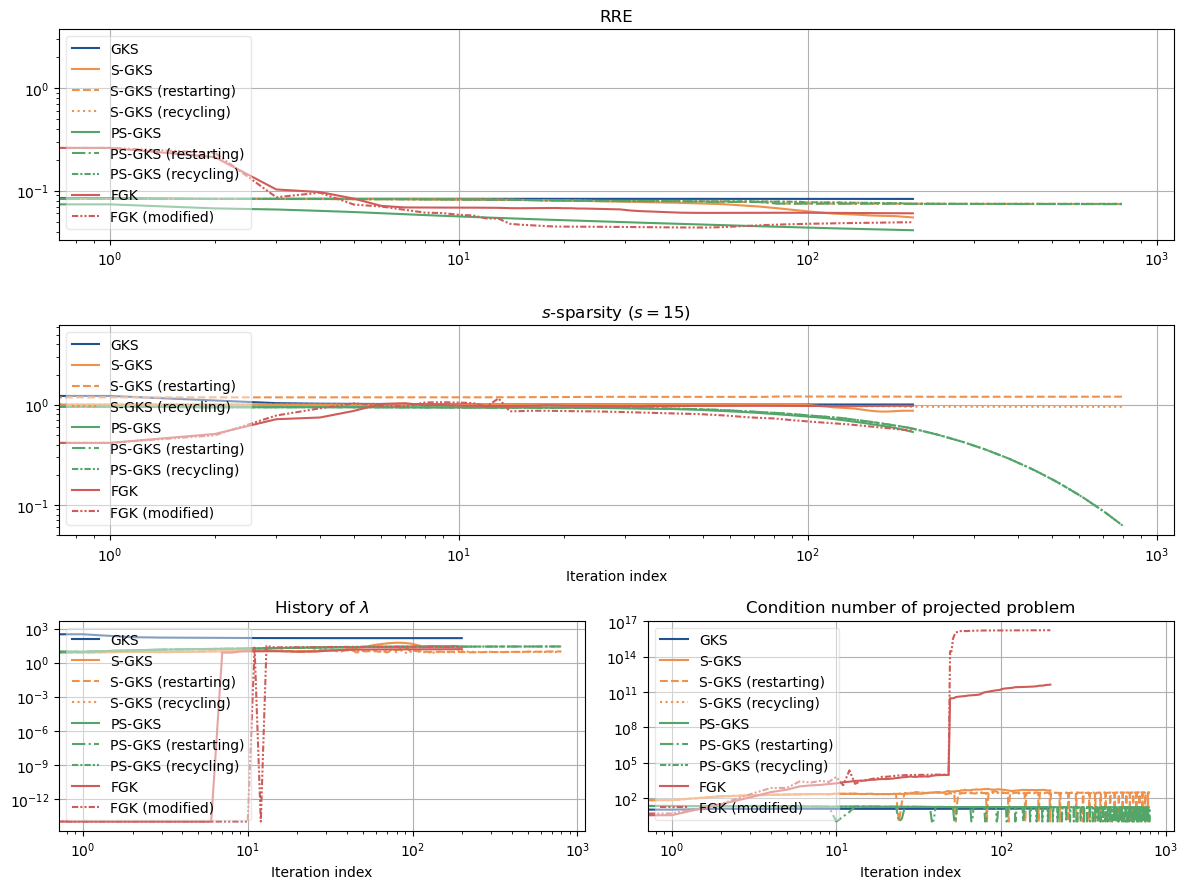

In [119]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 2, figure=fig)


ax3 = fig.add_subplot(gs[0,:])
ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
#ax3.set_xscale("log")
ax3.set_title("RRE")
#ax3.set_xlabel("Iteration index")
ax3.set_xscale("log")
ax3.legend(loc="upper right")
ax3.legend().get_frame().set_alpha(0.45)
ax3.grid()



ax4 = fig.add_subplot(gs[2,0])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend(loc="upper left").get_frame().set_alpha(0.45)
ax4.set_xscale("log")
ax4.grid()
#ax4.legend().get_frame().set_alpha(0.45)



ax6 = fig.add_subplot(gs[1,:])
ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax6.set_title("$s$-sparsity ($s = 15$)")
ax6.set_xlabel("Iteration index")
#ax6.set_xlim(None, 10**3)
ax6.set_xscale("log")
ax6.legend(loc="upper right")
ax6.legend(loc="upper left").get_frame().set_alpha(0.45)
ax6.grid()


ax5 = fig.add_subplot(gs[2, 1])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.set_xscale("log")
ax5.legend(loc="upper left").get_frame().set_alpha(0.45)
ax5.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_performance.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_performance.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


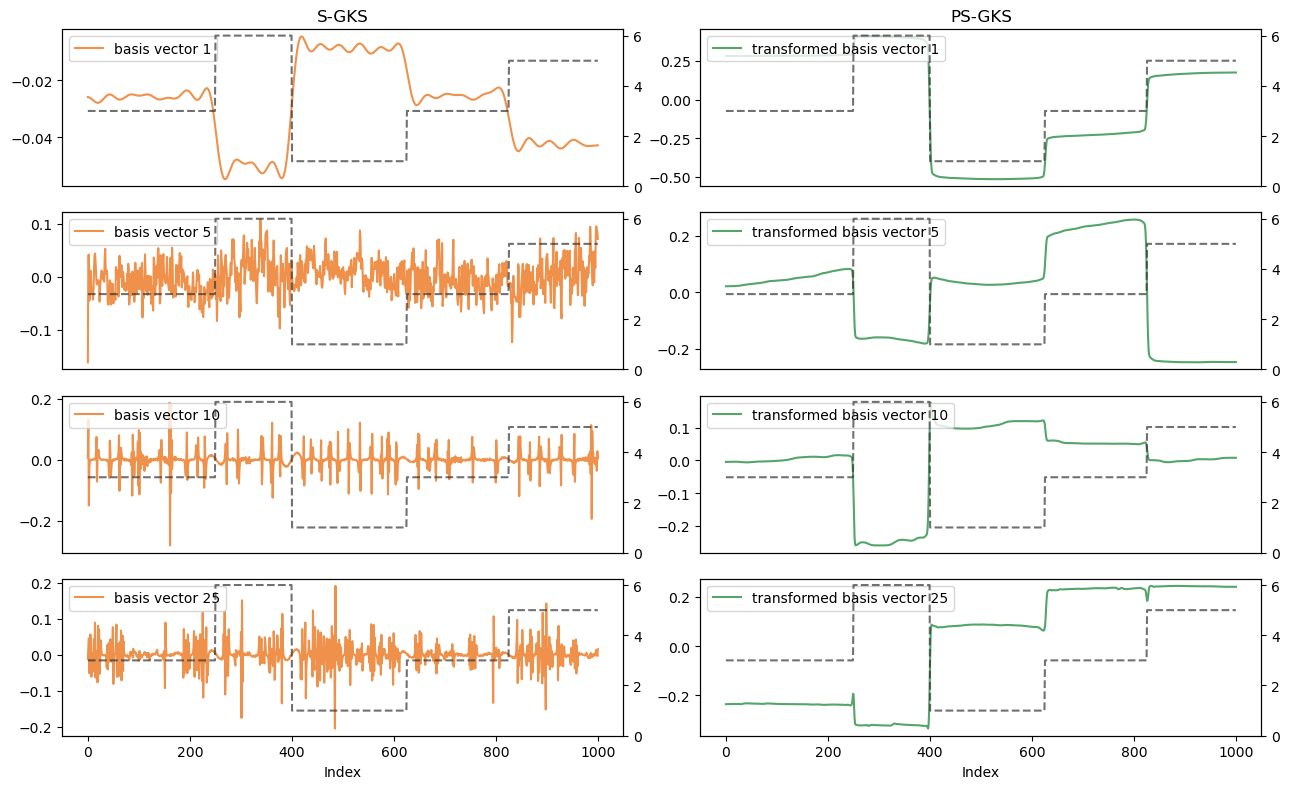

In [97]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")
axst = axs[0,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])
axst = axs[1,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])
axst = axs[2,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[3,0].legend(loc=loc)
axs[3,0].set_xlabel("Index")
axst = axs[3,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")
axst = axs[0,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])
axst = axs[1,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])
axst = axs[2,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[3,1].legend(loc=loc)
axs[3,1].set_xlabel("Index")
axst = axs[3,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

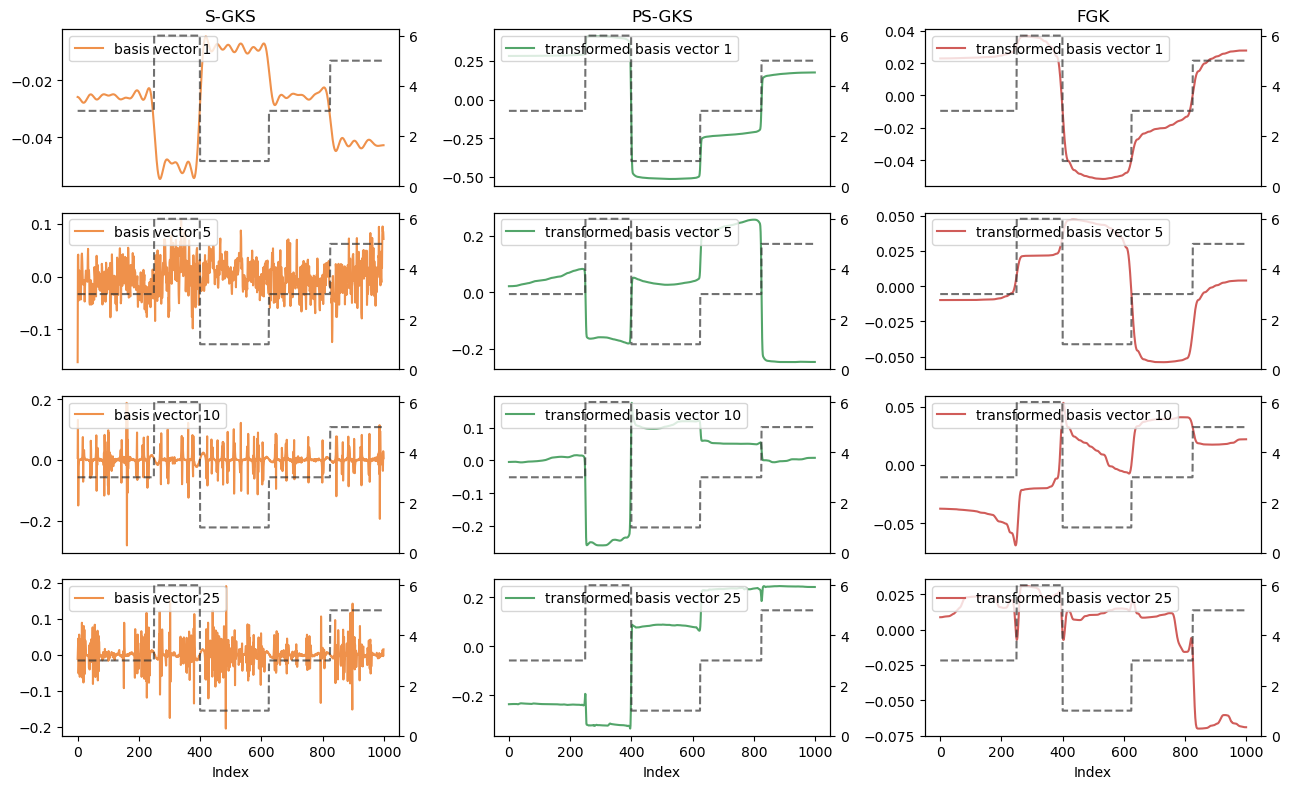

In [30]:
# fig, axs = plt.subplots(4,3, figsize=(13,8))

# loc = "upper left"

# kk = 0
# axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[0,0].legend(loc=loc)
# axs[0,0].set_xticks([])
# axs[0,0].set_title("S-GKS")
# axst = axs[0,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[1,0].legend(loc=loc)
# axs[1,0].set_xticks([])
# axst = axs[1,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[2,0].legend(loc=loc)
# axs[2,0].set_xticks([])
# axst = axs[2,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[3,0].legend(loc=loc)
# axs[3,0].set_xlabel("Index")
# axst = axs[3,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# kk = 0
# axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[0,1].legend(loc=loc)
# axs[0,1].set_xticks([])
# axs[0,1].set_title("PS-GKS")
# axst = axs[0,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[1,1].legend(loc=loc)
# axs[1,1].set_xticks([])
# axst = axs[1,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[2,1].legend(loc=loc)
# axs[2,1].set_xticks([])
# axst = axs[2,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[3,1].legend(loc=loc)
# axs[3,1].set_xlabel("Index")
# axst = axs[3,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])





# kk = 0
# axs[0,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[0,2].legend(loc=loc)
# axs[0,2].set_xticks([])
# axs[0,2].set_title("FGK")
# axst = axs[0,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[1,2].legend(loc=loc)
# axs[1,2].set_xticks([])
# axst = axs[1,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[2,2].legend(loc=loc)
# axs[2,2].set_xticks([])
# axst = axs[2,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[3,2].legend(loc=loc)
# axs[3,2].set_xlabel("Index")
# axst = axs[3,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# fig.tight_layout()
# #fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

# plt.show()

In [27]:
mmfkdata.keys()

dict_keys(['x', 'V', 'U', 'H', 'Z', 'w', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history'])